# E3

### Misión 1. Web scraping con Pandas

Vamos a leer las tablas HTML de la página, luego se identifica la tabla de PIB por sus encabezados y se crea un df con nombres simples y valores numéricos. 

Se usan las tres fuentes de la tabla: FMI, Banco Mundial y Naciones Unidas

In [1]:
import io
import pandas as pd
import requests

url_pib = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url_pib, headers=headers)
print(f"Código de respuesta: {response.status_code}")

tablas = pd.read_html(io.StringIO(response.text))
print(f"\nTablas encontradas: {len(tablas)}")
for i, tabla in enumerate(tablas):
    print(f"Tabla {i}: {tabla.shape[0]} filas x {tabla.shape[1]} columnas")
    print(f"  Columnas: {list(tabla.columns)[:5]}")

Código de respuesta: 200

Tablas encontradas: 8
Tabla 0: 1 filas x 1 columnas
  Columnas: [0]
Tabla 1: 1 filas x 2 columnas
  Columnas: [0, 1]
Tabla 2: 222 filas x 4 columnas
  Columnas: ['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']
Tabla 3: 14 filas x 3 columnas
  Columnas: ['Regional groupings', 'IMF (2026)[1]', 'World Bank (2024)[6]']
Tabla 4: 8 filas x 2 columnas
  Columnas: ['vteLists of countries by financial rankings', 'vteLists of countries by financial rankings.1']
Tabla 5: 9 filas x 2 columnas
  Columnas: ['vteLists of countries by GDP rankings', 'vteLists of countries by GDP rankings.1']
Tabla 6: 13 filas x 2 columnas
  Columnas: ['vteEconomic classification of countries', 'vteEconomic classification of countries.1']
Tabla 7: 2 filas x 2 columnas
  Columnas: [0, 1]


In [2]:
# identificar la tabla de países: debe tener columnas para país, FMI y Banco Mundial.
tabla_pib = None
for i, tabla in enumerate(tablas):
    nombres_columnas = " ".join([str(col).lower() for col in tabla.columns])
    print(nombres_columnas)
    if "country" in nombres_columnas and "imf" in nombres_columnas and "world bank" in nombres_columnas:
        tabla_pib = tabla
        print(f"Tabla principal del PIB: tabla {i}")
        break

# Las columnas pueden contener encabezados de más de un nivel
for col in tabla_pib.columns:
    nombre = str(col).lower()
    if "country" in nombre:
        col_pais = col
    elif "imf" in nombre:
        col_fmi = col
    elif "world bank" in nombre:
        col_bm = col
    elif "united nations" in nombre:
        col_onu = col

print("Columnas seleccionadas:")
print(col_pais, col_fmi, col_bm, col_onu)

0
0 1
country/territory imf (2026)[1] world bank (2025)[6] united nations (2024)[7]
Tabla principal del PIB: tabla 2
Columnas seleccionadas:
Country/Territory IMF (2026)[1] World Bank (2025)[6] United Nations (2024)[7]


In [3]:
# Limpiar el nombre del país y convertir el PIB desde texto a número.
# los valores ausentes o no numéricos se representan con None.
datos_pib = []
for _, fila in tabla_pib.iterrows():
    pais = str(fila[col_pais]).split("[")[0].strip()
    if pais in ["", "nan", "World", "Country/Territory"]:
        continue

    valores = []
    for col in [col_fmi, col_bm, col_onu]:
        texto = str(fila[col]).split("[")[0].replace(",", "").strip()
        try:
            numero = float(texto)
        except (ValueError, TypeError):
            numero = None
        valores.append(numero)

    # vamos a excluir filas sin ningún dato de PIB (por ejemplo encabezados repetidos).
    if valores == [None, None, None]:
        continue

    datos_pib.append({
        "Country": pais,
        "IMF": valores[0],
        "World Bank": valores[1],
        "United Nations": valores[2]
    })

df_pib = pd.DataFrame(datos_pib)
df_pib.columns = ["pais", "pib_fmi", "pib_banco_mundial", "pib_onu"]
print(f"Total de países y territorios obtenidos: {len(df_pib)}")
print("Tipos de datos:")
print(df_pib.dtypes)
display(df_pib.head())

Total de países y territorios obtenidos: 213
Tipos de datos:
pais                     str
pib_fmi              float64
pib_banco_mundial    float64
pib_onu              float64
dtype: object


,pais,pib_fmi,pib_banco_mundial,pib_onu
0,United States,32642373.0,30769700.0,29298000.0
1,China,21546403.0,19498039.0,18743802.0
2,Germany,5471299.0,5050923.0,4659929.0
3,Japan,4341986.0,4435163.0,4026211.0
4,United Kingdom,4268446.0,4002588.0,3685881.0


### Misión 2. Web scraping con BeautifulSoup

Se utiliza la página de **Chile**. Se extraen todas sus secciones `h2`, diez enlaces internos y al menos tres pares *atributo–valor* del infobox.

In [4]:
from bs4 import BeautifulSoup

url_chile = "https://en.wikipedia.org/wiki/Chile"
response = requests.get(url_chile, headers=headers)
print(f"Código de respuesta: {response.status_code}")

soup = BeautifulSoup(response.text, "html.parser")
print(f"Título: {soup.title.text}")

Código de respuesta: 200
Título: Chile - Wikipedia


In [5]:
encabezados = soup.find_all("h2")
secciones = [h.text.strip() for h in encabezados]
print(f"Secciones h2 ({len(secciones)}):")
print(secciones)

Secciones h2 (12):
['Contents', 'Etymology', 'History', 'Geography', 'Government and politics', 'Economy', 'Demographics', 'Culture', 'See also', 'References', 'Further reading', 'External links']


In [6]:
links = soup.find_all("a", href=True)
wiki_links = [link for link in links if link["href"].startswith("/wiki/")]

print("Primeros 10 enlaces internos de Wikipedia:")
for link in wiki_links[:10]:
    texto = link.text.strip()
    url = "https://en.wikipedia.org" + link["href"]
    print(f"{texto}: {url}")

Primeros 10 enlaces internos de Wikipedia:
Main page: https://en.wikipedia.org/wiki/Main_Page
Contents: https://en.wikipedia.org/wiki/Wikipedia:Contents
Current events: https://en.wikipedia.org/wiki/Portal:Current_events
Random article: https://en.wikipedia.org/wiki/Special:Random
About Wikipedia: https://en.wikipedia.org/wiki/Wikipedia:About
Help: https://en.wikipedia.org/wiki/Help:Contents
Learn to edit: https://en.wikipedia.org/wiki/Help:Introduction
Community portal: https://en.wikipedia.org/wiki/Wikipedia:Community_portal
Recent changes: https://en.wikipedia.org/wiki/Special:RecentChanges
Upload file: https://en.wikipedia.org/wiki/Wikipedia:File_upload_wizard


In [7]:
infobox = soup.find("table", class_="infobox")
if infobox is None:
    raise Exception("No se encontró el infobox de Chile")

datos_infobox = {}
for fila in infobox.find_all("tr"):
    encabezado = fila.find("th")
    valor = fila.find("td")
    if encabezado is not None and valor is not None:
        nombre_dato = encabezado.text.strip()
        texto_dato = valor.text.strip()
        if nombre_dato != "" and texto_dato != "" and len(datos_infobox) < 5:
            datos_infobox[nombre_dato] = texto_dato

print(f"Datos extraídos del infobox: {len(datos_infobox)}")
if len(datos_infobox) < 3:
    raise Exception("El infobox tiene menos de tres datos disponibles")
for nombre, valor in datos_infobox.items():
    print(f"{nombre}: {valor} ")

Datos extraídos del infobox: 5
Capitaland largest city: Santiago[a]33°26′S 70°40′W﻿ / ﻿33.433°S 70.667°W﻿ / -33.433; -70.667 
National language: Spanish 
Other spoken languages: Aymara
Kawésqar
Mapudungun
Quechua
Rapa Nui 
Religion  (2024)[1]: 73.1% Christianity
54.0% Catholic
16.3% Protestant
2.8% other Christians
25.8% no religion0.2% Judaism0.1% Buddhism0.1% Islam0.7% other religions 
Demonym: Chilean 


### Misión 3. API de Open-Meteo

Se consultan **12 capitales sudamericanas**, con los nombres y coordenadas del ejemplo de la sesión. La categoría `region` organiza las capitales en grupos dentro de Sudamérica, para poder comparar sus promedios en la misión 5.

Las variables consultadas son `temperature_2m`, `wind_speed_10m` y `relative_humidity_2m`. Se verifica el código HTTP y se espera 0,5 segundos entre solicitudes.

In [8]:
import time

# Las 12 capitales y coordenadas provienen del ejemplo del resumen de scraping/APIs.
capitales = {
    "Brazil": ("Brasília", -15.78, -47.93),
    "Colombia": ("Bogotá", 4.71, -74.07),
    "Argentina": ("Buenos Aires", -34.61, -58.38),
    "Peru": ("Lima", -12.05, -77.04),
    "Venezuela": ("Caracas", 10.49, -66.88),
    "Chile": ("Santiago", -33.45, -70.67),
    "Ecuador": ("Quito", -0.18, -78.47),
    "Bolivia": ("La Paz", -16.50, -68.15),
    "Paraguay": ("Asunción", -25.26, -57.58),
    "Uruguay": ("Montevideo", -34.88, -56.17),
    "Guyana": ("Georgetown", 6.80, -58.16),
    "Suriname": ("Paramaribo", 5.87, -55.17)
}

# Grupos geográficos para las consultas, todos pertenecen a Sudamérica
regiones = {
    "Brazil": "Este", "Colombia": "Norte", "Argentina": "Cono Sur",
    "Peru": "Andina", "Venezuela": "Norte", "Chile": "Cono Sur",
    "Ecuador": "Andina", "Bolivia": "Andina", "Paraguay": "Cono Sur",
    "Uruguay": "Cono Sur", "Guyana": "Norte", "Suriname": "Norte"
}

In [9]:
url_api = "https://api.open-meteo.com/v1/forecast"
datos_clima = []

for pais, (capital, lat, lon) in capitales.items():
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,wind_speed_10m,relative_humidity_2m"
    }
    response = requests.get(url_api, params=params)
    if response.status_code == 200:
        current = response.json()["current"]
        datos_clima.append({
            "ciudad": capital,
            "pais": pais,
            "region": regiones[pais],
            "latitud": lat,
            "longitud": lon,
            "temperatura": current["temperature_2m"],
            "viento": current["wind_speed_10m"],
            "humedad": current["relative_humidity_2m"]
        })
        print(f"{capital}: {current['temperature_2m']} °C")
    else:
        print(f"Error en {capital}: código {response.status_code}")
    time.sleep(0.5)

df_clima = pd.DataFrame(datos_clima)
print(f"Capitales consultadas correctamente: {len(df_clima)}")
if len(df_clima) < 10:
    raise Exception("Se necesitan al menos 10 capitales con datos meteorológicos")
display(df_clima)

Brasília: 19.0 °C
Bogotá: 13.3 °C
Buenos Aires: 22.4 °C
Lima: 24.1 °C
Caracas: 22.4 °C
Santiago: 24.2 °C
Quito: 11.2 °C
La Paz: 9.6 °C
Asunción: 26.0 °C
Montevideo: 20.3 °C
Georgetown: 27.5 °C
Paramaribo: 26.8 °C
Capitales consultadas correctamente: 12


,ciudad,pais,region,latitud,longitud,temperatura,viento,humedad
0,Brasília,Brazil,Este,-15.78,-47.93,19.0,0.9,94
1,Bogotá,Colombia,Norte,4.71,-74.07,13.3,2.6,84
2,Buenos Aires,Argentina,Cono Sur,-34.61,-58.38,22.4,12.0,72
3,Lima,Peru,Andina,-12.05,-77.04,24.1,10.4,83
4,Caracas,Venezuela,Norte,10.49,-66.88,22.4,3.0,80
5,Santiago,Chile,Cono Sur,-33.45,-70.67,24.2,0.7,61
6,Quito,Ecuador,Andina,-0.18,-78.47,11.2,2.9,95
7,La Paz,Bolivia,Andina,-16.50,-68.15,9.6,6.5,75
8,Asunción,Paraguay,Cono Sur,-25.26,-57.58,26.0,7.4,86
9,Montevideo,Uruguay,Cono Sur,-34.88,-56.17,20.3,17.9,82


### Misión 4. Combinación y almacenamiento en SQLite

Modelo de tres tablas:

- **Paises** (`pid` PK): país y valores de PIB de la misión 1. Para los países con una capital consultada, también contiene capital, continente, región y coordenadas.
- **Clima** (`cid` PK, `pais_id` FK): observaciones de temperatura, viento y humedad de la misión 3.
- **DatosInfobox** (`iid` PK, `pais_id` FK): los atributos del infobox de Chile extraídos en la misión 2.

Se activan las llaves foráneas y se crea `datos_web.db` desde cero cada vez que se ejecuta el cuaderno.

In [10]:
import sqlite3
import os

connection = sqlite3.connect("datos_web.db")
cursor = connection.cursor()
cursor.execute("PRAGMA foreign_keys = ON")

cursor.execute("""
    CREATE TABLE Paises (
        pid INTEGER PRIMARY KEY,
        nombre TEXT UNIQUE NOT NULL,
        pib_fmi REAL,
        pib_banco_mundial REAL,
        pib_onu REAL,
        capital TEXT,
        continente TEXT,
        region TEXT,
        latitud REAL,
        longitud REAL
    )
""")

cursor.execute("""
    CREATE TABLE Clima (
        cid INTEGER PRIMARY KEY,
        pais_id INTEGER NOT NULL,
        temperatura REAL NOT NULL,
        viento REAL NOT NULL,
        humedad REAL NOT NULL,
        FOREIGN KEY (pais_id) REFERENCES Paises(pid)
    )
""")

cursor.execute("""
    CREATE TABLE DatosInfobox (
        iid INTEGER PRIMARY KEY,
        pais_id INTEGER NOT NULL,
        atributo TEXT NOT NULL,
        valor TEXT NOT NULL,
        FOREIGN KEY (pais_id) REFERENCES Paises(pid)
    )
""")
connection.commit()
print("Tablas creadas: Paises, Clima y DatosInfobox")

Tablas creadas: Paises, Clima y DatosInfobox


In [11]:
# Cargar el PIB y guardar los ID asignados a cada país.
paises_map = {}
pid = 1

for _, fila in df_pib.iterrows():
    pais = fila["pais"]
    if pais not in paises_map:
        cursor.execute("""
            INSERT INTO Paises(nombre, pib_fmi, pib_banco_mundial, pib_onu)
            VALUES (?, ?, ?, ?)
        """, (pais, fila["pib_fmi"], fila["pib_banco_mundial"], fila["pib_onu"]))
        paises_map[pais] = pid
        pid += 1

# incorporar información de las capitales y cargar su clima
for _, fila in df_clima.iterrows():
    pais = fila["pais"]
    if pais in paises_map:
        cursor.execute("""
            UPDATE Paises
            SET capital = ?, continente = ?, region = ?, latitud = ?, longitud = ?
            WHERE pid = ?
        """, (fila["ciudad"], "América del Sur", fila["region"], fila["latitud"],
              fila["longitud"], paises_map[pais]))
        cursor.execute("""
            INSERT INTO Clima(pais_id, temperatura, viento, humedad)
            VALUES (?, ?, ?, ?)
        """, (paises_map[pais], fila["temperatura"],
              fila["viento"], fila["humedad"]))
    else:
        print(f"El país {pais} no fue encontrado en la tabla de PIB")

# incorporar la información scrapeada del infobox de Chile.
if "Chile" in paises_map:
    for atributo, valor in datos_infobox.items():
        cursor.execute("""
            INSERT INTO DatosInfobox(pais_id, atributo, valor)
            VALUES (?, ?, ?)
        """, (paises_map["Chile"], atributo, valor))

connection.commit()

In [12]:
# comprobar la cantidad de registros de cada tabla.
for tabla in ["Paises", "Clima", "DatosInfobox"]:
    cursor.execute(f"SELECT COUNT(*) FROM {tabla}")
    print(f"{tabla}: {cursor.fetchone()[0]} registros")

print("\nEjemplo de combinación entre PIB y clima:")
cursor.execute("""
    SELECT P.nombre, P.capital, P.pib_fmi, C.temperatura
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    LIMIT 5
""")
for resultado in cursor.fetchall():
    print(resultado)

Paises: 213 registros
Clima: 12 registros
DatosInfobox: 5 registros

Ejemplo de combinación entre PIB y clima:
('Brazil', 'Brasília', 2654761.0, 19.0)
('Colombia', 'Bogotá', 572735.0, 13.3)
('Argentina', 'Buenos Aires', 768206.0, 22.4)
('Peru', 'Lima', 399593.0, 24.1)
('Venezuela', 'Caracas', 111303.0, 22.4)


### Misión 5. Consultas SQL

1. Las 5 capitales más calurosas y las 5 más frías

In [13]:
print("5 capitales más calurosas:")
cursor.execute("""
    SELECT P.capital, P.nombre, C.temperatura
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    ORDER BY C.temperatura DESC
    LIMIT 5
""")
for resultado in cursor.fetchall():
    print(resultado)

print("\n5 capitales más frías:")
cursor.execute("""
    SELECT P.capital, P.nombre, C.temperatura
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    ORDER BY C.temperatura ASC
    LIMIT 5
""")
for resultado in cursor.fetchall():
    print(resultado)

5 capitales más calurosas:
('Georgetown', 'Guyana', 27.5)
('Paramaribo', 'Suriname', 26.8)
('Asunción', 'Paraguay', 26.0)
('Santiago', 'Chile', 24.2)
('Lima', 'Peru', 24.1)

5 capitales más frías:
('La Paz', 'Bolivia', 9.6)
('Quito', 'Ecuador', 11.2)
('Bogotá', 'Colombia', 13.3)
('Brasília', 'Brazil', 19.0)
('Montevideo', 'Uruguay', 20.3)


No se ve una relación tan clara entre la temperatura y la latitud. Vemos que Quito y Asución presentan temperaturas radicalmente diferentes, siendo que Quito está en pleno ecuador y Asunción en el sur de Sudamérica.

La latitud, entonces, no es lo único que termina determinando la temperatura de una ciudad.

2. Temperatura y humedad promedio por región

In [14]:
cursor.execute("""
    SELECT P.region, AVG(C.temperatura), AVG(C.humedad)
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    GROUP BY P.region
    ORDER BY P.region
""")
print("Región | Temperatura promedio (°C) | Humedad promedio (%)")
for resultado in cursor.fetchall():
    print(resultado)

Región | Temperatura promedio (°C) | Humedad promedio (%)
('Andina', 14.966666666666667, 84.33333333333333)
('Cono Sur', 23.225, 75.25)
('Este', 19.0, 94.0)
('Norte', 22.5, 83.5)


3. Ciudad con la mayor velocidad del viento

In [15]:
cursor.execute("""
    SELECT P.capital, P.nombre, C.viento
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    ORDER BY C.viento DESC
    LIMIT 1
""")
print(cursor.fetchone())

('Montevideo', 'Uruguay', 17.9)


4. Ciudades con humedad superior al promedio del dataset

In [16]:
cursor.execute("""
    SELECT P.capital, P.nombre, C.humedad
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    WHERE C.humedad > (SELECT AVG(humedad) FROM Clima)
    ORDER BY C.humedad DESC
""")
for resultado in cursor.fetchall():
    print(resultado)

('Quito', 'Ecuador', 95.0)
('Brasília', 'Brazil', 94.0)
('Asunción', 'Paraguay', 86.0)
('Georgetown', 'Guyana', 85.0)
('Paramaribo', 'Suriname', 85.0)
('Bogotá', 'Colombia', 84.0)
('Lima', 'Peru', 83.0)
('Montevideo', 'Uruguay', 82.0)


5. Latitud y temperatura

Se ordenan las capitales por latitud para comparar sus temperaturas. 

Como las mediciones son actuales y dependen también de otros factores, la tabla sirve para **explorar** el patrón y no basta por sí sola para afirmar una relación causal, claramente

In [17]:
pares = []
cursor.execute("""
    SELECT P.capital, P.nombre, P.latitud, C.temperatura
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    ORDER BY P.latitud ASC
""")
print("Capital | País | Latitud | Temperatura (°C)")
for resultado in cursor.fetchall():
    print(resultado)
    pares.append((resultado[2], resultado[3]))

Capital | País | Latitud | Temperatura (°C)
('Montevideo', 'Uruguay', -34.88, 20.3)
('Buenos Aires', 'Argentina', -34.61, 22.4)
('Santiago', 'Chile', -33.45, 24.2)
('Asunción', 'Paraguay', -25.26, 26.0)
('La Paz', 'Bolivia', -16.5, 9.6)
('Brasília', 'Brazil', -15.78, 19.0)
('Lima', 'Peru', -12.05, 24.1)
('Quito', 'Ecuador', -0.18, 11.2)
('Bogotá', 'Colombia', 4.71, 13.3)
('Paramaribo', 'Suriname', 5.87, 26.8)
('Georgetown', 'Guyana', 6.8, 27.5)
('Caracas', 'Venezuela', 10.49, 22.4)


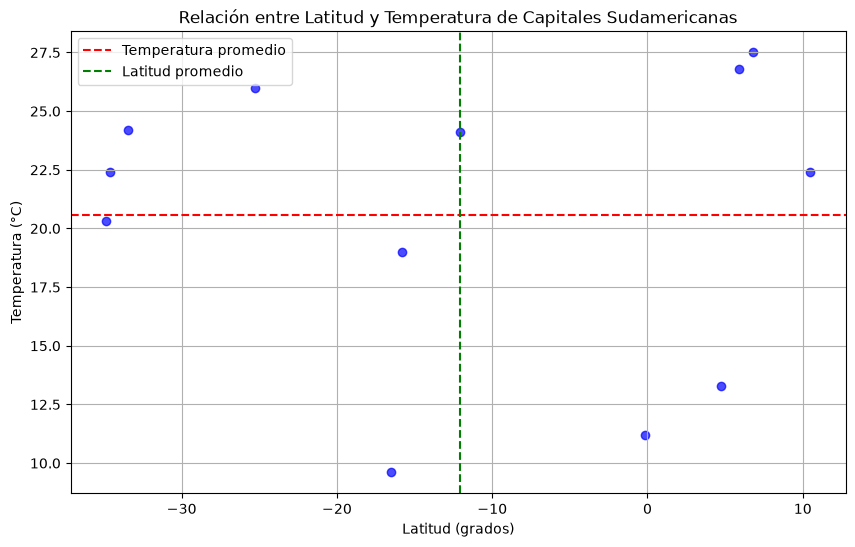

In [18]:
import matplotlib.pyplot as plt
latitudes, temperaturas = zip(*pares)
plt.figure(figsize=(10, 6))
plt.scatter(latitudes, temperaturas, color='blue', alpha=0.7)
plt.title('Relación entre Latitud y Temperatura de Capitales Sudamericanas')
plt.xlabel('Latitud (grados)')
plt.ylabel('Temperatura (°C)')
plt.axhline(y=sum(temperaturas)/len(temperaturas), color='red', linestyle='--', label='Temperatura promedio')
plt.axvline(x=sum(latitudes)/len(latitudes), color='green', linestyle='--', label='Latitud promedio')
plt.legend()
plt.grid()

6. Capitales con temperatura superior al promedio de su continente

Las 12 capitales del ejemplo son sudamericanas; por eso, esta consulta compara cada temperatura con el promedio de **América del Sur** dentro del dataset.

In [19]:
cursor.execute("""
    SELECT P.capital, P.nombre, P.continente, C.temperatura
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    WHERE C.temperatura > (
        SELECT AVG(C2.temperatura)
        FROM Paises P2
        JOIN Clima C2 ON P2.pid = C2.pais_id
        WHERE P2.continente = P.continente
    )
    ORDER BY P.continente, C.temperatura DESC
""")
for resultado in cursor.fetchall():
    print(resultado)

('Georgetown', 'Guyana', 'América del Sur', 27.5)
('Paramaribo', 'Suriname', 'América del Sur', 26.8)
('Asunción', 'Paraguay', 'América del Sur', 26.0)
('Santiago', 'Chile', 'América del Sur', 24.2)
('Lima', 'Peru', 'América del Sur', 24.1)
('Buenos Aires', 'Argentina', 'América del Sur', 22.4)
('Caracas', 'Venezuela', 'América del Sur', 22.4)


In [20]:
connection.close()